# Лабораторная работа 4. Математика CNN и FGSM-атаки

**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам Лекции 3**

**Формат:** индивидуально

**Среда:** Python, PyTorch, torchvision

## Цель работы
Закрепить математический аппарат свёртки и рецептивного поля, а также научиться конструировать и анализировать evasion-атаку методом Fast Gradient Sign Method (FGSM) на реальной свёрточной сети.

## Результаты обучения
После выполнения работы вы должны уметь:
- рассчитывать размер выходной карты признаков и рецептивное поле для произвольной конфигурации свёрточных слоёв;
- объяснять архитектурные решения LeNet, AlexNet, VGG, ResNet и их мотивацию;
- реализовывать FGSM-атаку по формуле $ x_{adv} = x + \epsilon \cdot \text{sign}(\nabla_x J(\theta, x, y)) $;
- строить и интерпретировать зависимость Attack Success Rate от бюджета $\epsilon$;
- применять adversarial training как базовую меру защиты.

## Как пользоваться этим ноутбуком
- Ячейки с `# TODO` необходимо заполнить самостоятельно.
- Ячейки с текстом **"Вопрос для отчёта"** требуют письменного ответа в markdown-ячейке ниже.
- Перед сдачей: Kernel → Restart & Run All, ноутбук должен выполняться от начала до конца без ошибок.


Почему обычный пайплайн не спасает (бэкпроп -> оптимизатор -> регуляризация):

Обычная регуляризация не знает, что существует направление, в котором нужно изменить пиксели, чтобы сломать модель. FGSM находит это направление через градиент. Поэтому Гудфеллоу предложил: «Давайте мы будем на каждом шаге обучения генерировать такого «врага» (FGSM-пример) и говорить модели: «Смотри, вот это — кот, хоть он и выглядит как гиббон. Учись!»».

## 0. Подготовка окружения

In [ ]:
# TODO: импортируйте необходимые библиотеки
# Подсказка: numpy, matplotlib, torch, torch.nn, torch.nn.functional, torchvision

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets

RANDOM_STATE = 42

# TODO: зафиксируйте seed для torch и numpy
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)
    # Для воспроизводимости на GPU (может замедлить обучение, но гарантирует одинаковый результат)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# TODO: определите device (cuda, если доступна, иначе cpu)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используется устройство: {device}")


Используется устройство: cpu


## Часть I. Математика CNN

### 1.1. Расчёт размера feature map

**Задание:** реализуйте функцию расчёта размера выходной карты признаков по формуле

$ H_{out} = \left\lfloor \frac{H - k + 2p}{s} \right\rfloor + 1 $

и рассчитайте её для заданных конфигураций.

In [ ]:
# TODO: реализуйте функцию
def conv_output_size(H, k, s, p):
    return (H - k + 2 * p) // s + 1

# Рассчитайте H_out для следующих конфигураций и заполните таблицу результатов
configs = [
    {"H": 224, "k": 7, "s": 2, "p": 3},
    {"H": 224, "k": 3, "s": 1, "p": 1},
    {"H": 56,  "k": 3, "s": 2, "p": 1},
    {"H": 28,  "k": 5, "s": 1, "p": 0},
]

# TODO: примените conv_output_size ко всем конфигурациям и выведите результат
print(f"{'H':>5} | {'k':>3} | {'s':>3} | {'p':>3} | {'H_out':>6}")
print("-" * 35)
for cfg in configs:
    H_out = conv_output_size(cfg["H"], cfg["k"], cfg["s"], cfg["p"])
    print(f"{cfg['H']:>5} | {cfg['k']:>3} | {cfg['s']:>3} | {cfg['p']:>3} | {H_out:>6}")


    H |   k |   s |   p |  H_out
-----------------------------------
  224 |   7 |   2 |   3 |    112
  224 |   3 |   1 |   1 |    224
   56 |   3 |   2 |   1 |     28
   28 |   5 |   1 |   0 |     24


### 1.2. Рецептивное поле

**Задание:** реализуйте функцию расчёта рецептивного поля по рекуррентной формуле

$ RF_L = RF_{L-1} + (k_L - 1)\prod_{i=1}^{L-1} s_i $

и сравните рецептивное поле для двух архитектурных решений с одинаковым итоговым покрытием, но разным числом параметров (в духе аргумента VGG о малых ядрах).

In [ ]:
# TODO: реализуйте функцию
def receptive_field(layers):
    """
    layers — список пар (kernel_size, stride).
    Возвращает RF после прохождения всех слоёв.
    """
    rf = 1          # начальное рецептивное поле
    jump = 1        # накопленное произведение страйдов
    for k, s in layers:
        rf = rf + (k - 1) * jump
        jump = jump * s
    return rf

# Вариант А: три слоя 3x3 (stride=1)
layers_a = [(3, 1), (3, 1), (3, 1)]
# Вариант Б: один слой 7x7 (stride=1)
layers_b = [(7, 1)]

# TODO: рассчитайте RF для обоих вариантов и сравните
rf_a = receptive_field(layers_a)
rf_b = receptive_field(layers_b)

print(f"Вариант А (3×3 → 3×3 → 3×3): RF = {rf_a}")
print(f"Вариант Б (один 7×7):         RF = {rf_b}")
print(f"Одинаковое покрытие: {rf_a == rf_b}")

Вариант А (3×3 → 3×3 → 3×3): RF = 7
Вариант Б (один 7×7):         RF = 7
Одинаковое покрытие: True


In [ ]:
# TODO: рассчитайте и сравните число обучаемых параметров для вариантов А и Б
# при числе входных/выходных каналов C = 64 (без учёта bias)
# Формула для k x k свёртки с C входными и C выходными каналами: k^2 * C^2

C = 64
# TODO

# Вариант А: три свёртки 3×3
params_a = 3 * (3**2 * C**2)

# Вариант Б: одна свёртка 7×7
params_b = 7**2 * C**2

print(f"Вариант А (3 × 3×3, C={C}): {params_a:,} параметров")
print(f"Вариант Б (1 × 7×7, C={C}): {params_b:,} параметров")
print(f"Отношение Б/А: {params_b / params_a:.3f}")
print(f"Экономия в варианте А: {(1 - params_a / params_b) * 100:.1f}%")

Вариант А (3 × 3×3, C=64): 110,592 параметров
Вариант Б (1 × 7×7, C=64): 200,704 параметров
Отношение Б/А: 1.815
Экономия в варианте А: 44.9%


**Вопрос для отчёта:** при одинаковом рецептивном поле какой вариант (А или Б) эффективнее по числу параметров и почему? Как это соотносится с архитектурным принципом VGG?

_Ваш ответ:_

Вариант А (три слоя 3×3) эффективнее: он использует ~110K параметров против ~200K у варианта Б (одно ядро 7×7) при одинаковом рецептивном поле 7×7. Экономия ~45%.

Почему: число параметров растёт в квадрате, а покрытие линейно. Поэтому много малых ядер «дешевле» одного большого при том же рецептивное поле.

Связь с VGG: этот аргумент лёг в основу архитектурного принципа VGG — использовать только ядра 3×3 и наращивать глубину через повторение блоков. Это даёт то же рецептивное поле при меньшем числе параметров.

### 1.3. Собственная свёрточная архитектура

**Задание:** спроектируйте небольшую CNN для классификации MNIST (2–3 свёрточных слоя + пулинг + полносвязный классификатор). Рассчитайте вручную (в markdown-ячейке) итоговое рецептивное поле последнего свёрточного слоя перед тем, как реализовывать сеть в коде.

_Ручной расчёт рецептивного поля вашей архитектуры (формулы и числа):_

### Архитектура CNN для MNIST

| Слой | Параметры | Выход |
|------|-----------|-------|
| Вход | 1×28×28 | 1×28×28 |
| Conv1 | 3×3, s=1, p=1, 32 канала | 32×28×28 |
| MaxPool1 | 2×2, s=2 | 32×14×14 |
| Conv2 | 3×3, s=1, p=1, 64 канала | 64×14×14 |
| MaxPool2 | 2×2, s=2 | 64×7×7 |
| Conv3 | 3×3, s=1, p=1, 128 каналов | 128×7×7 |
| FC | 128×7×7 → 10 | 10 |

### Расчёт рецептивного поля последнего свёрточного слоя (Conv3)

Формула:  

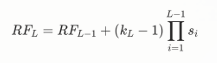

| Слой | \(k\) | \(s\) | \(RF\) | jump |
|------|------|------|--------|------|
| Conv1 | 3 | 1 | 3 | 1 |
| Pool1 | 2 | 2 | 4 | 2 |
| Conv2 | 3 | 1 | 8 | 2 |
| Pool2 | 2 | 2 | 10 | 4 |
| Conv3 | 3 | 1 | **18** | 4 |

**Итог:** рецептивное поле последнего свёрточного слоя = **18×18** пикселей исходного изображения.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# TODO: реализуйте класс вашей CNN
class MyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Свёрточные слои: k=3, s=1, p=1 (размер сохраняется)
        self.conv1 = nn.Conv2d(in_channels=1,  out_channels=32,  kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64,  kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1)

        # Пулинг: окно 2×2, страйд 2 (размер делится пополам)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Полносвязный классификатор: 128×7×7 → 10
        self.fc = nn.Linear(128 * 7 * 7, 10)

    def forward(self, x):
        # x: [B, 1, 28, 28]

        x = F.relu(self.conv1(x))   # [B, 32, 28, 28]
        x = self.pool(x)            # [B, 32, 14, 14]

        x = F.relu(self.conv2(x))   # [B, 64, 14, 14]
        x = self.pool(x)            # [B, 64, 7, 7]

        x = F.relu(self.conv3(x))   # [B, 128, 7, 7]

        x = torch.flatten(x, start_dim=1)  # [B, 128*7*7]
        x = self.fc(x)              # [B, 10]
        return x


## Часть II. Данные и обучение базовой модели

In [ ]:
# TODO: загрузите MNIST через torchvision.datasets
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST(root='./data', train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False, num_workers=2)

print(f"Обучающих примеров: {len(train_dataset)}")
print(f"Тестовых примеров:  {len(test_dataset)}")


Обучающих примеров: 60000
Тестовых примеров:  10000


In [ ]:
# TODO: обучите вашу модель MyCNN на train_loader (2-3 эпохи достаточно)
# Используйте CrossEntropyLoss и Adam

model = MyCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

EPOCHS = 3

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total
    print(f"Epoch {epoch+1}/{EPOCHS} | loss={train_loss:.4f} | acc={train_acc:.4f}")


Epoch 1/3 | loss=0.2056 | acc=0.9374
Epoch 2/3 | loss=0.0506 | acc=0.9847
Epoch 3/3 | loss=0.0347 | acc=0.9894


In [ ]:
# TODO: оцените точность на тестовой выборке (clean accuracy)
# Сохраните значение в переменную clean_accuracy для дальнейшего использования

model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        preds = model(images).argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

clean_accuracy = correct / total
print(f"Clean accuracy: {clean_accuracy:.4f}")


Clean accuracy: 0.9909


## Часть III. FGSM-атака

### 3.1. Реализация FGSM

**Задание:** реализуйте функцию FGSM-атаки по формуле

$ x_{adv} = x + \epsilon \cdot \text{sign}(\nabla_x J(\theta, x, y)) $

Функция должна принимать модель, батч изображений и меток, значение $\epsilon$ и возвращать adversarial-примеры.

In [ ]:
# TODO: реализуйте функцию FGSM-атаки
def fgsm_attack(model, x, y, epsilon, criterion):
    # 1. Клонируем вход и включаем отслеживание градиента
    x_adv = x.clone().detach().requires_grad_(True)

    # 2. Прямой проход
    logits = model(x_adv)

    # 3. Считаем loss
    loss = criterion(logits, y)

    # 4. Обратный проход: градиент loss по x_adv
    model.zero_grad()
    loss.backward()

    # 5. Возмущение: epsilon * sign(градиент)
    with torch.no_grad():
        perturbation = epsilon * x_adv.grad.sign()
        # 6. Добавляем и ограничиваем в [0, 1]
        x_adv = x_adv + perturbation
        x_adv = torch.clamp(x_adv, 0.0, 1.0)

    return x_adv.detach()


### 3.2. Визуализация атаки на одном примере

**Задание:** выберите один тестовый пример, постройте для него adversarial-версию при $\epsilon = 0.2$ и визуализируйте три изображения: оригинал, возмущение, adversarial-пример — с указанием предсказаний модели и уверенности (confidence) для каждого.

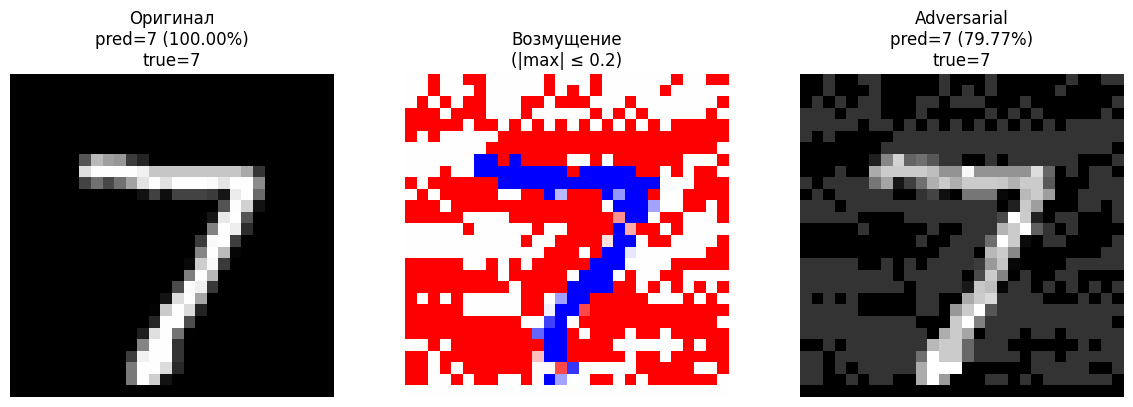

Истинная метка: 7
До атаки:  pred=7, confidence=100.00%
После атаки: pred=7, confidence=79.77%
Максимальное изменение пикселя: 0.2000


In [ ]:
# TODO: выберите пример из test_loader
# TODO: примените fgsm_attack
# TODO: получите предсказания модели на оригинале и adversarial-примере (класс + confidence через softmax)
# TODO: постройте matplotlib-визуализацию из 3 подграфиков

import matplotlib.pyplot as plt

# TODO: выберите пример из test_loader
model.eval()
images, labels = next(iter(test_loader))
idx = 0  # можно поменять, чтобы посмотреть другой пример

x = images[idx:idx+1].to(device)          # [1, 1, 28, 28]
y = labels[idx:idx+1].to(device)
x_np = x.cpu().squeeze().numpy()           # [28, 28]

# TODO: примените fgsm_attack
epsilon = 0.2
x_adv = fgsm_attack(model, x, y, epsilon, criterion)

# TODO: получите предсказания модели на оригинале и adversarial-примере
with torch.no_grad():
    logits_clean = model(x)
    logits_adv   = model(x_adv)

    prob_clean = F.softmax(logits_clean, dim=1)[0]
    prob_adv   = F.softmax(logits_adv,   dim=1)[0]

pred_clean = prob_clean.argmax().item()
pred_adv   = prob_adv.argmax().item()
conf_clean = prob_clean.max().item()
conf_adv   = prob_adv.max().item()

x_adv_np = x_adv.cpu().squeeze().numpy()
perturbation = x_adv_np - x_np             # разница (возмущение)

# TODO: постройте matplotlib-визуализацию из 3 подграфиков
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(x_np, cmap='gray')
axes[0].set_title(f"Оригинал\npred={pred_clean} ({conf_clean:.2%})\ntrue={y.item()}")
axes[0].axis('off')

axes[1].imshow(perturbation, cmap='bwr', vmin=-epsilon, vmax=epsilon)
axes[1].set_title(f"Возмущение\n(|max| ≤ {epsilon})")
axes[1].axis('off')

axes[2].imshow(x_adv_np, cmap='gray')
axes[2].set_title(f"Adversarial\npred={pred_adv} ({conf_adv:.2%})\ntrue={y.item()}")
axes[2].axis('off')

plt.tight_layout()
plt.show()

print(f"Истинная метка: {y.item()}")
print(f"До атаки:  pred={pred_clean}, confidence={conf_clean:.2%}")
print(f"После атаки: pred={pred_adv}, confidence={conf_adv:.2%}")
print(f"Максимальное изменение пикселя: {np.abs(perturbation).max():.4f}")


**Вопрос для отчёта:** удалось ли изменить предсказание модели? Является ли визуально заметным возмущение? Какой класс присвоила модель adversarial-примеру?

_Ваш ответ:_
Предсказание модели изменить не удалось, удалось лишь снизить уверенность на 20 %. Возмущение является визуально заметным (какие то помехи просто), но не влияет на восприятие цифры.

### 3.3. Attack Success Rate в зависимости от ε

**Задание:** постройте график зависимости Attack Success Rate (доли тестовых примеров, на которых атака меняет предсказание) от бюджета \(\epsilon\) для набора значений \(\epsilon \in \{0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3\}\).

ε = 0.00 | ASR = 0.0000
ε = 0.02 | ASR = 0.0102
ε = 0.05 | ASR = 0.0422
ε = 0.10 | ASR = 0.1594
ε = 0.15 | ASR = 0.3980
ε = 0.20 | ASR = 0.6945
ε = 0.30 | ASR = 0.9648


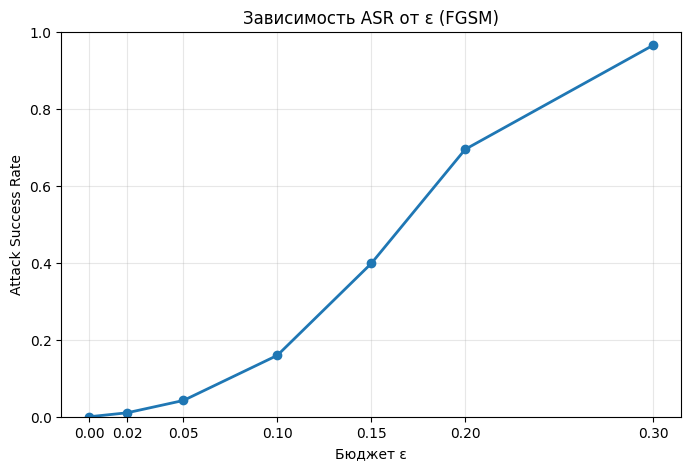

In [ ]:
def evaluate_asr(model, loader, epsilon, criterion, n_batches=10):
    model.eval()
    total = 0
    changed = 0

    for i, (images, labels) in enumerate(loader):
        if i >= n_batches:
            break
        images, labels = images.to(device), labels.to(device)

        # Предсказание на чистых данных — здесь градиенты не нужны
        with torch.no_grad():
            pred_clean = model(images).argmax(dim=1)

        # FGSM — здесь градиенты НУЖНЫ, никакого no_grad
        if epsilon > 0:
            x_adv = fgsm_attack(model, images, labels, epsilon, criterion)
        else:
            x_adv = images

        # Предсказание на adversarial — снова без градиентов
        with torch.no_grad():
            pred_adv = model(x_adv).argmax(dim=1)

        changed += (pred_clean != pred_adv).sum().item()
        total += labels.size(0)

    return changed / total


epsilons = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
asr_values = []

for eps in epsilons:
    asr = evaluate_asr(model, test_loader, eps, criterion, n_batches=10)
    asr_values.append(asr)
    print(f"ε = {eps:.2f} | ASR = {asr:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(epsilons, asr_values, marker='o', linewidth=2)
plt.xlabel("Бюджет ε")
plt.ylabel("Attack Success Rate")
plt.title("Зависимость ASR от ε (FGSM)")
plt.grid(True, alpha=0.3)
plt.xticks(epsilons)
plt.ylim(0, 1)
plt.show()

**Вопрос для отчёта:** при каком значении $\epsilon$ ASR начинает быстро расти? Совместимо ли это значение с визуальной незаметностью возмущения (сравните с примером из п.3.2)?

_Ваш ответ:_
ASR начинает быстро расти уже при значении $\epsilon$ 0.1. Такое значение вообще практически незаметно с точки зрения восприятия цифры глазом.

## Часть IV. Adversarial training

**Задание:** обучите вторую модель (такую же архитектуру, как MyCNN) с использованием adversarial training по формуле

$ \tilde{J}(\theta, x, y) = \alpha J(\theta, x, y) + (1-\alpha) J(\theta, x_{adv}, y) $

с $\alpha = 0.5$ и $\epsilon$, использованным при обучении, равным одному из средних значений из п.3.3.

In [ ]:
# TODO: реализуйте цикл adversarial training
# На каждом шаге:
# 1. Постройте x_adv через fgsm_attack для текущего батча
# 2. Посчитайте комбинированный loss (alpha * loss_clean + (1-alpha) * loss_adv)
# 3. Сделайте шаг оптимизации

adv_model = MyCNN().to(device)
adv_optimizer = torch.optim.Adam(adv_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

ALPHA = 0.5
EPS_TRAIN = 0.15   # среднее значение из п.3.3 (зона быстрого роста ASR)
EPOCHS_ADV = 3

for epoch in range(EPOCHS_ADV):
    adv_model.train()
    running_loss = 0.0
    correct_clean = 0
    correct_adv = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # 1. Генерируем adversarial примеры для текущего батча
        #    Важно: используем текущие веса модели, но backward от FGSM
        #    не должен трогать веса — только вход.
        x_adv = fgsm_attack(adv_model, images, labels, EPS_TRAIN, criterion)

        # 2. Комбинированный loss
        logits_clean = adv_model(images)
        logits_adv   = adv_model(x_adv)

        loss_clean = criterion(logits_clean, labels)
        loss_adv   = criterion(logits_adv,   labels)
        loss = ALPHA * loss_clean + (1 - ALPHA) * loss_adv

        # 3. Шаг оптимизации
        adv_optimizer.zero_grad()
        loss.backward()
        adv_optimizer.step()

        running_loss += loss.item() * images.size(0)

        with torch.no_grad():
            correct_clean += (logits_clean.argmax(1) == labels).sum().item()
            correct_adv   += (logits_adv.argmax(1)   == labels).sum().item()
        total += labels.size(0)

    print(f"Epoch {epoch+1}/{EPOCHS_ADV} | loss={running_loss/total:.4f} "
          f"| acc_clean={correct_clean/total:.4f} | acc_adv={correct_adv/total:.4f}")


Epoch 1/3 | loss=0.3439 | acc_clean=0.9435 | acc_adv=0.8334
Epoch 2/3 | loss=0.1226 | acc_clean=0.9862 | acc_adv=0.9341
Epoch 3/3 | loss=0.0895 | acc_clean=0.9897 | acc_adv=0.9518


Clean accuracy обычной модели:  0.9909
Clean accuracy adv-модели:      0.9884
Просадка:                       0.25 п.п.
ε=0.00 | ASR обычной: 0.0000 | ASR adv: 0.0000
ε=0.02 | ASR обычной: 0.0102 | ASR adv: 0.0035
ε=0.05 | ASR обычной: 0.0422 | ASR adv: 0.0078
ε=0.10 | ASR обычной: 0.1594 | ASR adv: 0.0203
ε=0.15 | ASR обычной: 0.3980 | ASR adv: 0.0383
ε=0.20 | ASR обычной: 0.6945 | ASR adv: 0.0785
ε=0.30 | ASR обычной: 0.9648 | ASR adv: 0.2547


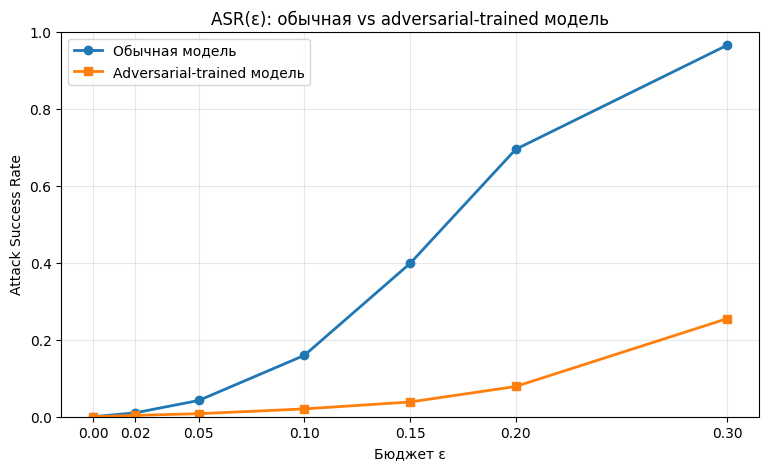

In [ ]:
# TODO: оцените clean accuracy adversarial-trained модели
# TODO: постройте график ASR(epsilon) для adv_model и сравните с обычной моделью на одном графике


adv_model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        preds = adv_model(images).argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

adv_clean_accuracy = correct / total
print(f"Clean accuracy обычной модели:  {clean_accuracy:.4f}")
print(f"Clean accuracy adv-модели:      {adv_clean_accuracy:.4f}")
print(f"Просадка:                       {(clean_accuracy - adv_clean_accuracy) * 100:.2f} п.п.")

epsilons = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]

asr_clean_model = []
asr_adv_model = []

for eps in epsilons:
    asr_clean_model.append(evaluate_asr(model,     test_loader, eps, criterion, n_batches=10))
    asr_adv_model.append(  evaluate_asr(adv_model, test_loader, eps, criterion, n_batches=10))
    print(f"ε={eps:.2f} | ASR обычной: {asr_clean_model[-1]:.4f} | ASR adv: {asr_adv_model[-1]:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(epsilons, asr_clean_model, marker='o', linewidth=2, label="Обычная модель")
plt.plot(epsilons, asr_adv_model,   marker='s', linewidth=2, label="Adversarial-trained модель")
plt.xlabel("Бюджет ε")
plt.ylabel("Attack Success Rate")
plt.title("ASR(ε): обычная vs adversarial-trained модель")
plt.grid(True, alpha=0.3)
plt.xticks(epsilons)
plt.ylim(0, 1)
plt.legend()
plt.show()

**Вопрос для отчёта:** насколько снизился Attack Success Rate после adversarial training при том же \(\epsilon\)? Изменилась ли clean accuracy (точность на чистых данных)? Согласуется ли это с ограничением FGSM-adversarial training, упомянутым в лекции (устойчивость только к одношаговым атакам)?

_Ваш ответ:_
ASR снизился колоссально (до 10 раз), точность на чистых данных немного снизилась. С ограничением согласуется: наблюдается рост вскоре после повышения бюджета FGSM выше 0.15 (на каком тренировали).

## Часть V. Итоговый вывод

**Вопрос для отчёта:** сформулируйте связь между математическими свойствами CNN (высокая размерность входа, локальная связность) и существованием adversarial-примеров, опираясь на линейную гипотезу Гудфеллоу. Почему увеличение разрешения изображения потенциально увеличивает уязвимость модели к $L_\infty$-ограниченным атакам?

_Ваш ответ:_

CNN работает с изображениями, где очень много пикселей (тысячи-миллионы). По линейной гипотезе Гудфеллоу, даже крошечное изменение каждого пикселя на
ϵ
ϵ даёт суммарный сдвиг выхода, пропорциональный числу пикселей:

ϵ
⋅
∥
w
∥
1
∼
ϵ
⋅
n

Пикселей много -> сдвиг большой -> модель ломается.

Почему разрешение усиливает уязвимость: больше пикселей -> больше
n
-> при том же
ϵ
суммарный эффект сильнее. Атака становится эффективнее «бесплатно».

---
Выполните **не менее двух** из следующих заданий. Оформите результаты в отдельных ячейках ниже .

### С1. Влияние глубины архитектуры на устойчивость к FGSM
Обучите две версии MyCNN с разной глубиной (например, 2 и 5 свёрточных слоёв, при сопоставимом числе параметров) и сравните их ASR(ε). Свяжите результат с обсуждением иерархии признаков и рецептивного поля из лекции.

### С2. Целевая (targeted) FGSM-атака
Модифицируйте FGSM так, чтобы атака заставляла модель предсказывать конкретный целевой класс (а не просто любой неверный), минимизируя loss по целевому классу вместо максимизации loss по истинному. Сравните Success Rate целевой и нецелевой атаки при одинаковом ε.

### С3. Трансферируемость adversarial-примеров
Обучите две модели с разной архитектурой (например, разное число слоёв/каналов). Постройте adversarial-примеры для модели А методом FGSM и проверьте, насколько успешно они обманывают необученную на этих примерах модель Б. Свяжите результат со свойством трансферируемости, разобранным в лекции (Szegedy et al.).

### С4. Аналитическая иллюстрация линейной гипотезы
Реализуйте эксперимент из демонстрационного ноутбука (раздел «линейная гипотеза») самостоятельно: постройте график зависимости среднего сдвига выхода линейной модели \( w^T\eta^* = \epsilon\|w\|_1 \) от размерности входа \(n\) для нескольких значений \(\epsilon\) на одном графике. Объясните, почему это объясняет уязвимость моделей компьютерного зрения именно с ростом разрешения изображений.


Clean accuracy модели Б: 0.9825
ε=0.05 | ASR на A: 0.0422 | Перенос на B: 0.0234
ε=0.10 | ASR на A: 0.1594 | Перенос на B: 0.0898
ε=0.15 | ASR на A: 0.3980 | Перенос на B: 0.1891
ε=0.20 | ASR на A: 0.6945 | Перенос на B: 0.3672
ε=0.30 | ASR на A: 0.9648 | Перенос на B: 0.7926


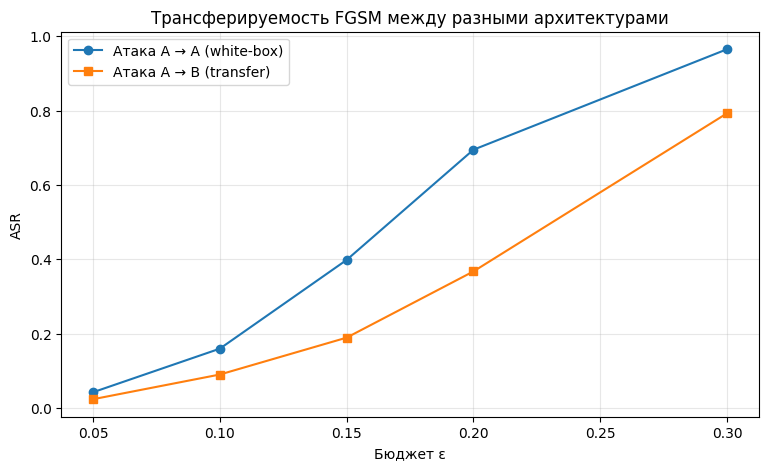

In [ ]:
# C3: обучаем вторую модель (другая архитектура) и проверяем перенос атаки

class MyCNN2(nn.Module):
    """Другая архитектура: меньше каналов, ядро 5×5 на первом слое."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=5, stride=1, padding=2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        self.fc    = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


# Обучаем модель Б (архитектура отличается)
model_B = MyCNN2().to(device)
opt_B = torch.optim.Adam(model_B.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()

for epoch in range(2):
    model_B.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        opt_B.zero_grad()
        loss = crit(model_B(images), labels)
        loss.backward()
        opt_B.step()

# Точность модели Б на чистых данных
model_B.eval()
correct = total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        correct += (model_B(images).argmax(1) == labels).sum().item()
        total += labels.size(0)
clean_B = correct / total
print(f"Clean accuracy модели Б: {clean_B:.4f}")

# Атакуем модель А (MyCNN) и проверяем, обманывает ли она модель Б
def transfer_asr(model_source, model_target, loader, epsilon, criterion, n_batches=10):
    model_source.eval(); model_target.eval()
    total = changed = 0
    for i, (images, labels) in enumerate(loader):
        if i >= n_batches: break
        images, labels = images.to(device), labels.to(device)

        x_adv = fgsm_attack(model_source, images, labels, epsilon, criterion)

        with torch.no_grad():
            pred_clean  = model_target(images).argmax(1)
            pred_adv    = model_target(x_adv).argmax(1)

        changed += (pred_clean != pred_adv).sum().item()
        total += labels.size(0)
    return changed / total


epsilons = [0.05, 0.1, 0.15, 0.2, 0.3]
asr_A_on_A, asr_A_on_B = [], []
for eps in epsilons:
    asr_A_on_A.append(evaluate_asr(model,     test_loader, eps, crit, 10))
    asr_A_on_B.append(transfer_asr(model,     model_B,    test_loader, eps, crit, 10))
    print(f"ε={eps:.2f} | ASR на A: {asr_A_on_A[-1]:.4f} | Перенос на B: {asr_A_on_B[-1]:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(epsilons, asr_A_on_A, marker='o', label="Атака A → A (white-box)")
plt.plot(epsilons, asr_A_on_B, marker='s', label="Атака A → B (transfer)")
plt.xlabel("Бюджет ε")
plt.ylabel("ASR")
plt.title("Трансферируемость FGSM между разными архитектурами")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Итого теория трансферируемости подтверждена. Сгенерировав adversarial примеры для модели А, эти же примеры нанесли урон и модели Б. Это значит, что можно обучить свою суррогатную модель на похожих данных, сделать adversarial римеры для нее и применить эти примеры к настоящей.

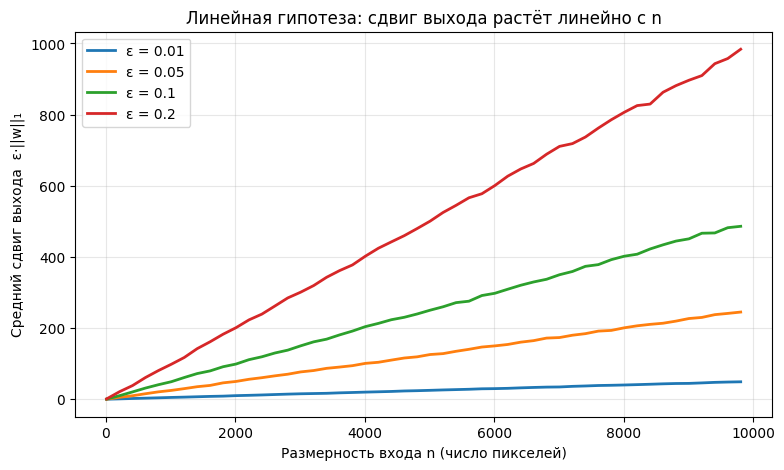

In [ ]:
# TODO: реализуйте выбранные задания (С1-С4) здесь
np.random.seed(RANDOM_STATE)

n_values = np.arange(10, 10001, 200)     # размерности входа
epsilons = [0.01, 0.05, 0.1, 0.2]

plt.figure(figsize=(9, 5))
for eps in epsilons:
    shifts = []
    for n in n_values:
        # w — случайные веса ~ U[0, 1], ||w||_1 ≈ n * mean|w| = n * 0.5
        w = np.random.uniform(0, 1, size=n)
        shifts.append(eps * np.abs(w).sum())
    plt.plot(n_values, shifts, linewidth=2, label=f"ε = {eps}")

plt.xlabel("Размерность входа n (число пикселей)")
plt.ylabel("Средний сдвиг выхода  ε·||w||₁")
plt.title("Линейная гипотеза: сдвиг выхода растёт линейно с n")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Объяснение роста угрозы: чем выше разрешение,тем меньший эпсилон потребуется для совершения атаки, атака будет дешевле с увеличением разрешения.

---


## Требования к сдаче
- Ноутбук выполняется целиком без ошибок (Kernel → Restart & Run All).
- Все `# TODO` заполнены, все вопросы для отчёта содержат письменный ответ.
- Обязательны: расчёт RF, реализация FGSM, график ASR(ε), сравнение с adversarial training.
